# Eksperimen & Evaluasi Segmentasi Pelanggan Agen Ikan Giling Ujok

Notebook ini adalah **lingkungan eksperimen dan evaluasi** (tahap *evaluasi pola* dalam kerangka KDD) untuk model RFM + K-Means yang dipakai sistem segmentasi.

**Prinsip penting:** notebook ini meng-import fungsi yang SAMA (utils.core_ml) dengan aplikasi Flask, bukan scikit-learn, sehingga hasil di notebook dijamin identik dengan hasil di sistem produksi.

Isi notebook:
1. Persiapan data dari database MySQL (sumber tunggal)
2. Elbow Method K=2..6 (justifikasi jumlah cluster)
3. Silhouette Score per K
4. Bukti empiris pentingnya normalisasi (membuktikan ulang Virmani et al., 2015)
5. Model final K=3 + distribusi segmen + interpretasi sentroid
6. Evaluasi ambang batas retrain
7. (Opsional) Export artefak model untuk dipakai sistem Flask

> Catatan metodologis: K-Means adalah *unsupervised learning*, tidak ada train/test split karena tidak ada label. Evaluasi memakai metrik internal (Elbow, Silhouette) terhadap seluruh data.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
print('Project root:', ROOT)

import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

from app import app
from utils.db import db
from models import Pelanggan, Transaksi
from utils.core_ml import (
    calculate_rfm, fit_model, score_with_model, check_retrain,
    calculate_elbow_method, calculate_silhouette_score,
    MinMaxScalerPure, KMeansPure, _fit_scalers_from_items, _normalize_items,
)

plt.style.use('seaborn-v0_8-whitegrid')

Project root: C:\Users\User\Bismillah Skripsi Safira


[*] Database 'ikan_giling_rfm' berhasil divalidasi/dibuat.


[*] Tabel database berhasil disinkronisasi.


## 1. Persiapan Data (tahap Data Selection + Transformation)

Data diambil langsung dari database yang sama dengan aplikasi web, lalu diolah menjadi nilai RFM.

In [2]:
with app.app_context():
    pelanggan_list = [{'id': p.id, 'nama_pelanggan': p.nama_pelanggan} for p in Pelanggan.query.all()]
    transaksi_list = [{
        'pelanggan_id': t.pelanggan_id,
        'tanggal_transaksi': t.tanggal_transaksi,
        'total_transaksi': float(t.total_transaksi),
    } for t in Transaksi.query.all()]

print(f'Jumlah pelanggan : {len(pelanggan_list)}')
print(f'Jumlah transaksi : {len(transaksi_list)}')

rfm_list = calculate_rfm(pelanggan_list, transaksi_list)
clustered = [x for x in rfm_list if x['frequency'] > 0]
print(f'Pelanggan bertransaksi (masuk clustering): {len(clustered)}')

import pandas as pd
df = pd.DataFrame(clustered)[['nama_pelanggan', 'recency', 'frequency', 'monetary', 'score_rfm']]
df.describe().round(2)

Jumlah pelanggan : 68
Jumlah transaksi : 557
Pelanggan bertransaksi (masuk clustering): 68


,recency,frequency,monetary,score_rfm
count,68.00,68.00,6.800000e+01,68.00
mean,250.22,8.19,2.961388e+07,2.00
std,8.41,6.66,3.220637e+07,0.76
min,244.00,1.00,5.320000e+05,1.00
25%,244.00,3.00,8.986750e+06,1.33
50%,247.00,7.00,1.865400e+07,2.00
75%,251.25,12.00,3.845600e+07,2.67
max,274.00,28.00,1.527530e+08,3.00


## 2. Elbow Method - K=2 sampai K=6

Mengukur inertia (SSE) untuk setiap K. Titik siku (*elbow point*) adalah K di mana penambahan cluster tidak lagi menurunkan SSE secara berarti.

K	Inertia (SSE)
2	6.6981
3	3.1554  <-- titik siku
4	2.1012
5	1.7232
6	1.2329

K optimal terdeteksi: 3


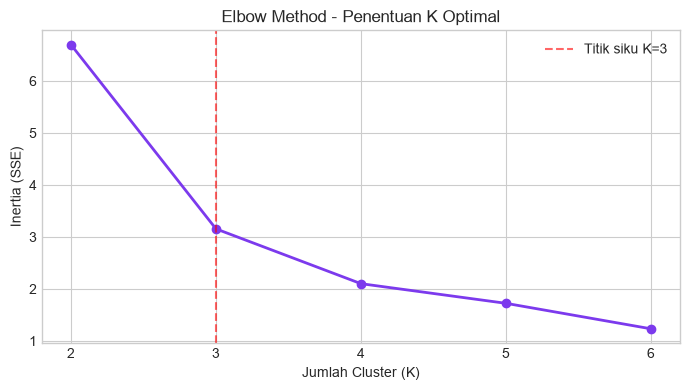

In [3]:
elbow = calculate_elbow_method(rfm_list, max_k=6)
print('K\tInertia (SSE)')
for k, sse in zip(elbow['k_values'], elbow['sse_values']):
    marker = '  <-- titik siku' if k == elbow['optimal_k'] else ''
    print(f'{k}\t{sse}{marker}')
print(f"\nK optimal terdeteksi: {elbow['optimal_k']}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(elbow['k_values'], elbow['sse_values'], 'o-', color='#7c3aed', linewidth=2)
ax.axvline(elbow['optimal_k'], color='red', linestyle='--', alpha=0.6, label=f"Titik siku K={elbow['optimal_k']}")
ax.set_xlabel('Jumlah Cluster (K)')
ax.set_ylabel('Inertia (SSE)')
ax.set_title('Elbow Method - Penentuan K Optimal')
ax.set_xticks(elbow['k_values'])
ax.legend()
plt.tight_layout()
plt.show()

## 3. Silhouette Score per K

Silhouette Coefficient rata-rata mengukur seberapa terpisah satu klaster dari klaster lain. Rentang: -1 s.d. 1, makin tinggi makin baik. Nilai > 0,5 umumnya dianggap struktur klaster yang baik.

K = 2 -> Silhouette = 0.3853
K = 3 -> Silhouette = 0.5050
K = 4 -> Silhouette = 0.4432
K = 5 -> Silhouette = 0.3827
K = 6 -> Silhouette = 0.4141


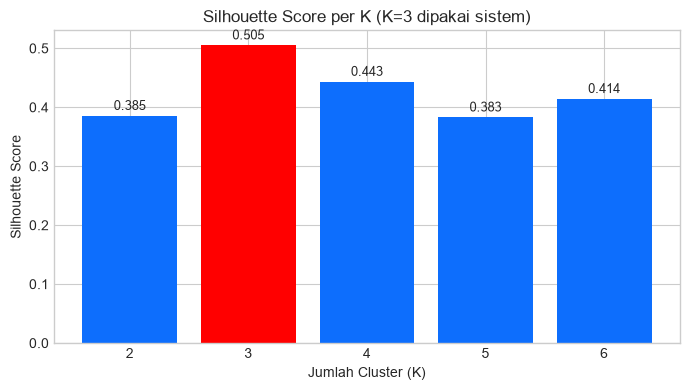


K dengan Silhouette tertinggi: 3 (nilai 0.5050)


In [4]:
scalers = _fit_scalers_from_items(clustered)
X = _normalize_items(clustered, scalers)

sil_by_k = {}
for k in range(2, 7):
    labels = KMeansPure(n_clusters=min(k, len(X))).fit(X).labels_
    sil_by_k[k] = calculate_silhouette_score(X, labels)
    print(f'K = {k} -> Silhouette = {sil_by_k[k]:.4f}')

fig, ax = plt.subplots(figsize=(7, 4))
colors = ['red' if k == 3 else '#0d6efd' for k in sil_by_k]
ax.bar(sil_by_k.keys(), sil_by_k.values(), color=colors)
ax.set_xlabel('Jumlah Cluster (K)')
ax.set_ylabel('Silhouette Score')
ax.set_title('Silhouette Score per K (K=3 dipakai sistem)')
ax.set_xticks(list(sil_by_k.keys()))
for k, v in sil_by_k.items():
    ax.text(k, v + 0.01, f'{v:.3f}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

best_k = max(sil_by_k, key=sil_by_k.get)
print(f'\nK dengan Silhouette tertinggi: {best_k} (nilai {sil_by_k[best_k]:.4f})')

## 4. Bukti Empiris: Pentingnya Normalisasi

Membuktikan ulang temuan **Virmani et al. (2015)** yang dikutip di Tinjauan Pustaka: normalisasi meningkatkan kualitas clustering pada data berskala berbeda.

Data RFM mentah memiliki skala sangat berbeda (Recency puluhan hari, Frequency puluhan kali, Monetary jutaan rupiah). Tanpa normalisasi, jarak Euclidean akan didominasi Monetary.

**Metodologi perbandingan:** kedua clustering (dengan/tanpa normalisasi) dievaluasi pada ruang ternormalisasi yang sama, karena Silhouette yang dihitung pada ruang berbeda tidak sebanding.

Silhouette (TANPA normalisasi, dievaluasi di ruang normalisasi): 0.2936
Silhouette (DENGAN normalisasi, dievaluasi di ruang normalisasi): 0.5050
Peningkatan: +0.2114

Distribusi cluster TANPA normalisasi : {0: 46, 1: 18, 2: 4}
Distribusi cluster DENGAN normalisasi: {0: 15, 1: 41, 2: 12}

Catatan: tanpa normalisasi, Monetary (skala jutaan) mendominasi jarak Euclidean,
sehingga Recency dan Frequency nyaris tidak berpengaruh -> klaster timpang.


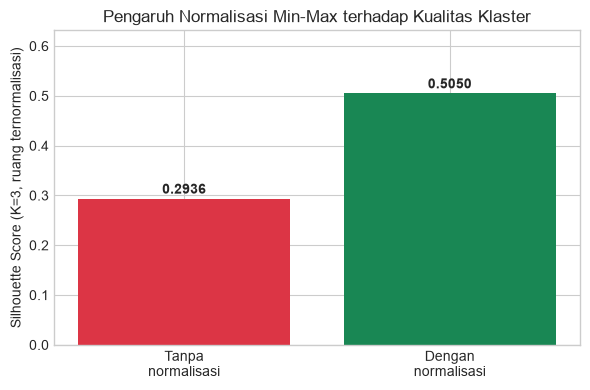

In [5]:
X_raw = [[float(x['recency']), float(x['frequency']), float(x['monetary'])] for x in clustered]

# Kedua clustering didefinisikan dulu...
lab_raw = KMeansPure(n_clusters=3).fit(X_raw).labels_   # clustering pada data MENTAH
lab_norm = KMeansPure(n_clusters=3).fit(X).labels_      # clustering pada data ternormalisasi

# ...lalu keduanya DIEVALUASI di ruang yang SAMA (ruang ternormalisasi, tempat sistem bekerja),
# agar Silhouette sebanding. Silhouette pada ruang berbeda TIDAK boleh dibandingkan langsung
# karena jaraknya dihitung pada skala berbeda.
sil_tanpa = calculate_silhouette_score(X, lab_raw)   # clustering mentah, dievaluasi di ruang norm
sil_dengan = calculate_silhouette_score(X, lab_norm) # clustering norm, dievaluasi di ruang norm

from collections import Counter
print(f'Silhouette (TANPA normalisasi, dievaluasi di ruang normalisasi): {sil_tanpa:.4f}')
print(f'Silhouette (DENGAN normalisasi, dievaluasi di ruang normalisasi): {sil_dengan:.4f}')
print(f'Peningkatan: {sil_dengan - sil_tanpa:+.4f}')
print()
print('Distribusi cluster TANPA normalisasi :', dict(sorted(Counter(lab_raw).items())))
print('Distribusi cluster DENGAN normalisasi:', dict(sorted(Counter(lab_norm).items())))
print()
print('Catatan: tanpa normalisasi, Monetary (skala jutaan) mendominasi jarak Euclidean,')
print('sehingga Recency dan Frequency nyaris tidak berpengaruh -> klaster timpang.')

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Tanpa\nnormalisasi', 'Dengan\nnormalisasi'], [sil_tanpa, sil_dengan], color=['#dc3545', '#198754'])
ax.set_ylabel('Silhouette Score (K=3, ruang ternormalisasi)')
ax.set_title('Pengaruh Normalisasi Min-Max terhadap Kualitas Klaster')
ax.set_ylim(0, max(sil_tanpa, sil_dengan) * 1.25)
for b, v in zip(bars, [sil_tanpa, sil_dengan]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.01, f'{v:.4f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Model Final K=3: Distribusi Segmen & Interpretasi Sentroid

Pelatihan model final menggunakan fungsi `fit_model` yang sama persis dengan tombol training di sistem Flask.

K                : 3
Data latih       : 68 pelanggan bertransaksi
Silhouette       : 0.505
Elbow optimal K  : 3
Mapping sentroid : {'2': [0, 'Pelanggan Loyal'], '1': [1, 'Pelanggan Aktif'], '0': [2, 'Pelanggan Non Aktif']}

Distribusi segmen:
segmentasi
Pelanggan Aktif        41
Pelanggan Non Aktif    15
Pelanggan Loyal        12


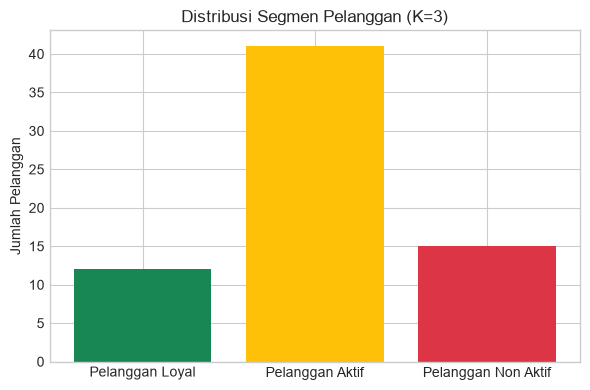

In [6]:
artifact = fit_model(rfm_list, alasan='notebook_eksperimen')
print(f"K                : {artifact['k']}")
print(f"Data latih       : {artifact['n_samples']} pelanggan bertransaksi")
print(f"Silhouette       : {artifact['metrics']['silhouette']}")
print(f"Elbow optimal K  : {artifact['metrics']['elbow']['optimal_k']}")
print(f"Mapping sentroid : {artifact['mapping']}")

hasil = score_with_model([dict(x) for x in rfm_list], artifact)

import pandas as pd
df_h = pd.DataFrame(hasil)
dist = df_h[df_h['frequency'] > 0]['segmentasi'].value_counts()
print('\nDistribusi segmen:')
print(dist.to_string())

fig, ax = plt.subplots(figsize=(6, 4))
urut = [s for s in ['Pelanggan Loyal', 'Pelanggan Aktif', 'Pelanggan Non Aktif'] if s in dist.index]
warna = {'Pelanggan Loyal': '#198754', 'Pelanggan Aktif': '#ffc107', 'Pelanggan Non Aktif': '#dc3545'}
ax.bar(urut, [dist[s] for s in urut], color=[warna[s] for s in urut])
ax.set_ylabel('Jumlah Pelanggan')
ax.set_title('Distribusi Segmen Pelanggan (K=3)')
plt.tight_layout()
plt.show()

In [7]:
# Interpretasi sentroid: ubah kembali ke skala asli agar bisa dibaca pemilik usaha
sp = artifact['scaler']
print('Interpretasi Sentroid (skala asli):')
print(f"{'Label':<22} {'Recency':>10} {'Frequency':>10} {'Monetary':>15}")
print('-' * 60)
for orig, (db_label, nama) in artifact['mapping'].items():
    c = artifact['centroids'][int(orig)]
    r_asli = c[0] * (sp['r']['max'] - sp['r']['min']) + sp['r']['min']
    f_asli = c[1] * (sp['f']['max'] - sp['f']['min']) + sp['f']['min']
    m_asli = c[2] * (sp['m']['max'] - sp['m']['min']) + sp['m']['min']
    print(f"C{db_label+1} {nama:<17} {r_asli:>8.1f}h {f_asli:>9.1f}x {m_asli:>14,.0f}")

Interpretasi Sentroid (skala asli):
Label                     Recency  Frequency        Monetary
------------------------------------------------------------
C1 Pelanggan Loyal      244.5h      19.1x     84,319,250
C2 Pelanggan Aktif      246.7h       7.3x     22,102,463
C3 Pelanggan Non Aktif    264.4h       1.8x      6,380,800


## 6. Evaluasi Ambang Batas Retrain

Sistem hanya melakukan retrain ketika salah satu ambang batas terpenuhi. Di sini kita cek kondisi model terhadap data terkini.

In [8]:
perlu, alasan, info = check_retrain(artifact, rfm_list)
print('Perlu retrain?', perlu)
for a in alasan:
    print('  -', a)
print('\nInfo evaluasi:')
for k, v in info.items():
    if k != 'thresholds':
        print(f'  {k}: {v}')
print('\nAmbang batas berlaku:', info.get('thresholds', {}))

Perlu retrain? False

Info evaluasi:
  umur_hari: 0
  n_samples_now: 68
  n_transaksi_now: 557
  pertambahan_pelanggan_pct: 0.0
  pertambahan_transaksi_pct: 0.0
  silhouette_aktual: 0.505
  drift_pct: 0.0

Ambang batas berlaku: {'data_baru_pct': 10.0, 'silhouette_min': 0.35, 'drift_pct': 10.0, 'umur_hari': 90}


## 7. (Opsional) Export Artefak Model untuk Sistem Flask

Sel berikut menyimpan hasil training sebagai versi baru ke **database** (tabel `ml_artifact` + registry `ml_models`) dan mengaktifkannya untuk sistem web, lalu menulis salinan JSON ke `models_ml/` sebagai lampiran bukti.\n
**Nonaktifkan `SAVE_MODEL = False` jika hanya ingin eksperimen** — menjalankan sel ini akan mengganti model aktif yang dipakai aplikasi.

Catatan: prinsip *single source of entry* — ekspor model produksi yang disarankan tetap lewat tombol **Retrain/Latih Model di sistem Flask**, notebook dipakai untuk eksperimen dan verifikasi angka. Gunakan sel ini hanya jika ingin model hasil eksperimen tertentu yang dipakai sistem.

In [9]:
SAVE_MODEL = False  # Ubah ke True untuk mengaktifkan model hasil notebook di sistem Flask

if SAVE_MODEL:
    from utils.model_store import save_model
    with app.app_context():
        versi, path = save_model(artifact, alasan='manual', export_json=True)\n    print(f'Model v{versi} disimpan ke {path} dan DIaktifkan untuk sistem Flask.')
else:
    print('SAVE_MODEL=False -> artefak TIDAK disimpan, model aktif sistem tidak berubah.')

SAVE_MODEL=False -> artefak TIDAK disimpan, model aktif sistem tidak berubah.


## Ringkasan Angka untuk Laporan

Sel berikut mencetak ringkasan angka yang bisa langsung dipakai di Bab Hasil skripsi.

In [10]:
print('=' * 60)
print('RINGKASAN EVALUASI MODEL SEGMENTASI')
print('=' * 60)
print(f"Jumlah data pelanggan (bertransaksi) : {artifact['n_samples']}")
print(f"Jumlah transaksi                     : {artifact['n_transaksi']}")
print(f"K yang digunakan                     : {artifact['k']}")
print(f"Elbow optimal K                      : {artifact['metrics']['elbow']['optimal_k']}")
print(f"Silhouette model (ruang norm)        : {artifact['metrics']['silhouette']}")
print(f"Silhouette clustering tanpa norm     : {sil_tanpa}")
print(f"Distribusi segmen                    : {dict(dist)}")
print('=' * 60)

RINGKASAN EVALUASI MODEL SEGMENTASI
Jumlah data pelanggan (bertransaksi) : 68
Jumlah transaksi                     : 557
K yang digunakan                     : 3
Elbow optimal K                      : 3
Silhouette model (ruang norm)        : 0.505
Silhouette clustering tanpa norm     : 0.2936
Distribusi segmen                    : {'Pelanggan Aktif': np.int64(41), 'Pelanggan Non Aktif': np.int64(15), 'Pelanggan Loyal': np.int64(12)}
